# Error Analysis on our NN & our LightGBM

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, classification_report
from home_credit_neural_network import HomeCreditNN, prepare_features

SEED = 420
SPLIT_FILE = "stratified_target"
FLAG_RATE = 0.20

In [2]:
train_merged = pd.read_parquet("data/processed/train_merged.parquet")

X, y = prepare_features(train_merged)
cat_col = X.select_dtypes(include=["object", "str"]).columns.tolist()  
X[cat_col] = X[cat_col].fillna("MISSING")

print(X.shape, f"{len(cat_col)} categorical")

(307511, 173) 16 categorical


In [3]:
s = duckdb.sql(f"SELECT SK_ID_CURR, split FROM 'data_splits/{SPLIT_FILE}.parquet'").df()
split = train_merged["SK_ID_CURR"].map(s.set_index("SK_ID_CURR")["split"])
tr, dv, va = [(split == k).to_numpy() for k in ["train", "dev", "validation"]]

for name, m in [("train", tr), ("dev", dv), ("validation", va)]:
    print(f"{name:<11} {m.sum():>7,} clients   default rate {y[m].mean():.2%}")

train       215,259 clients   default rate 8.07%
dev          46,125 clients   default rate 8.07%
validation   46,127 clients   default rate 8.07%


# LightGBM Training

In [ ]:
X_tree = X.copy()
for col in cat_col:
    cats = pd.Categorical(X.loc[tr, col]).categories # grabs every unique categories present in the training subset
    X_tree[col] = pd.Categorical(X[col], categories=cats) #makes the columns for the entire dataset, but explicitly forces it to use the training categories 

lgbm = lgb.LGBMClassifier(
    n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=100, 
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
    class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1
)

lgbm.fit(X_tree[tr], y[tr], eval_set=[(X_tree[dv], y[dv])], eval_metric="auc", 
         callbacks=[lgb.early_stopping(100, verbose=False)])
print("LightGBM best trees:", lgbm.best_iteration_)

c:\Users\Flami\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM best trees: 777


# Neural Network Training

In [6]:
NN = HomeCreditNN(class_weight="balanced", random_state=SEED, verbose=True)
NN.fit(X[tr], y[tr], X_val=X[dv], y_val=y[dv])

epoch  1  train loss 1.0984  val AUC 0.7690
epoch  2  train loss 1.0561  val AUC 0.7725
epoch  3  train loss 1.0442  val AUC 0.7726
epoch  4  train loss 1.0382  val AUC 0.7745
epoch  5  train loss 1.0322  val AUC 0.7750
epoch  6  train loss 1.0258  val AUC 0.7746
epoch  7  train loss 1.0183  val AUC 0.7746
epoch  8  train loss 1.0125  val AUC 0.7753
epoch  9  train loss 1.0066  val AUC 0.7738
epoch 10  train loss 0.9997  val AUC 0.7708
epoch 11  train loss 0.9934  val AUC 0.7740
epoch 12  train loss 0.9766  val AUC 0.7739
epoch 13  train loss 0.9675  val AUC 0.7690
early stop - best val AUC 0.7753


,class_weight,'balanced'
,hidden,"(256, ...)"
,dropout,0.3
,lr,0.001
,weight_decay,1e-05
,batch_size,1024
,max_epochs,50
,patience,5
,val_size,0.1
,random_state,420
,verbose,True


# Overall scores from both models 

In [8]:
preds = {
    "LightGBM": {"dev": lgbm.predict_proba(X_tree[dv])[:, 1], "val": lgbm.predict_proba(X_tree[va])[:, 1]},
    "Neural Network": {"dev": NN.predict_proba(X[dv])[:, 1], "val": NN.predict_proba(X[va])[:, 1]}
}

pd.DataFrame({
    name: {
        "dev_auc": roc_auc_score(y[dv], p["dev"]),
        "val_auc": roc_auc_score(y[va], p["val"]),
        "val_pr_auc": average_precision_score(y[va], p["val"])
    }
    for name, p in preds.items()
}).round(4) # creating a object list containing all metrics

,LightGBM,Neural Network
dev_auc,0.7859,0.7753
val_auc,0.7826,0.7736
val_pr_auc,0.2701,0.2563


In [10]:
X_va = X[va].copy()
y_va = y[va]
err = X_va.assign(TARGET=y_va)

# Code under here will flag what we can possbily review and conduct a fix. 
for name, p in preds.items():
    threshold = np.quantile(p["dev"], 1 - FLAG_RATE)
    pred = (p["val"] >= threshold).astype(int)
    key = "lgb" if name == "LightGBM" else "NN" # when grabbing anything it will set the key either to lgb or NN 
    err[f"p_{key}"] = p["val"]
    err[f"out_{key}"] = np.select(
        [(pred == 1) & (y_va == 1), (pred == 0) & (y_va == 1), (pred == 1) & (y_va == 0)],
        ["TP", "FN", "FP"], default = "TN"
    )
    print(f"\n=== {name}  (threshold {threshold:.3f}, flags {pred.mean():.1%} of validation) ===")
    print(confusion_matrix(y_va, pred))
    print(classification_report(y_va, pred, digits=3))


=== LightGBM  (threshold 0.571, flags 20.4% of validation) ===
[[35079  7324]
 [ 1641  2083]]
              precision    recall  f1-score   support

           0      0.955     0.827     0.887     42403
           1      0.221     0.559     0.317      3724

    accuracy                          0.806     46127
   macro avg      0.588     0.693     0.602     46127
weighted avg      0.896     0.806     0.841     46127


=== Neural Network  (threshold 0.624, flags 20.4% of validation) ===
[[35040  7363]
 [ 1688  2036]]
              precision    recall  f1-score   support

           0      0.954     0.826     0.886     42403
           1      0.217     0.547     0.310      3724

    accuracy                          0.804     46127
   macro avg      0.585     0.687     0.598     46127
weighted avg      0.895     0.804     0.839     46127



# Note
Our metrics particularly the recall scores from our validation set, clearly reflect how much our model underfits. It struggles classifying applicants that possbily will struggle with payments. 

# Default rate by risk decile 

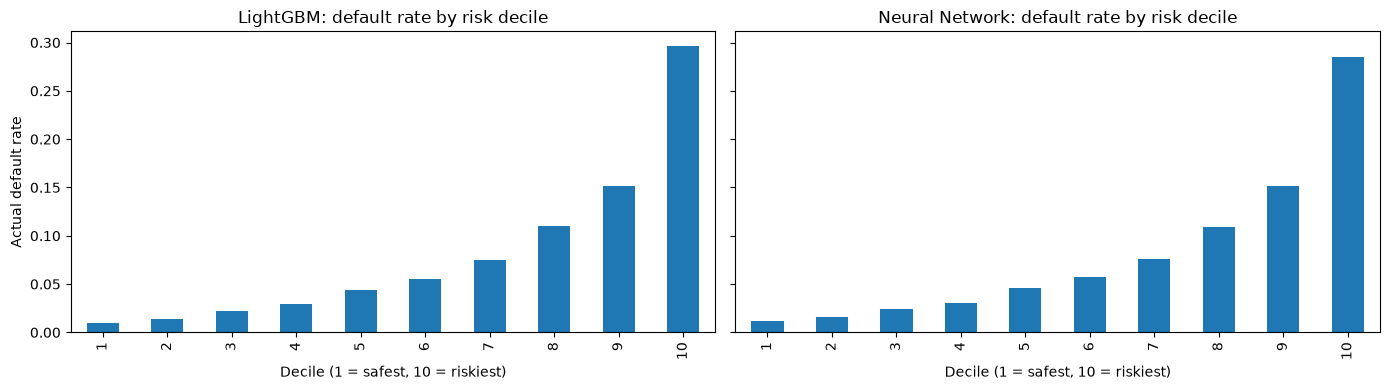

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, key, title in [(axes[0], "lgb", "LightGBM"), (axes[1], "NN", "Neural Network")]:
    dec = pd.qcut(err[f"p_{key}"].rank(method="first"), 10, labels=range(1, 11))
    rate = err.groupby(dec, observed=True)["TARGET"].mean()
    rate.plot.bar(ax=ax)
    ax.set_title(f"{title}: default rate by risk decile")
    ax.set_xlabel("Decile (1 = safest, 10 = riskiest)")
    ax.set_ylabel("Actual default rate")
plt.tight_layout()
plt.show()


# Note: 
Best way to understand is Decile 10, 10% of people who are the riskiest, around 30% of those 100 applicants, we are predicting around 30 people actually defaulted. 

# Where each model strugles (by segment)

In [14]:
err["age_band"] = pd.cut(err["AGE_YEARS"], [20, 30, 40, 50, 60, 70])
err["ext3_band"] = pd.qcut(err["EXT_SOURCE_3"], 5)
err["has_bureau"] = err["bureau_n_loans"].notna()
err["has_ext1"] = err["EXT_SOURCE_1"].notna()
err["has_credit_card"] = err["cc_n_cards"].notna()

def segment_report(seg):
    rows = []
    for level, g in err.groupby(seg, observed=True):
        if g["TARGET"].nunique() < 2 or len(g) < 200:
            continue
        defaulters, repaid = (g["TARGET"] == 1).sum(), (g["TARGET"] == 0).sum()
        rows.append({
            "segment": level,
            "clients": len(g),
            "default_rate": g["TARGET"].mean(),
            "lgb_auc": roc_auc_score(g["TARGET"], g["p_lgb"]),
            "nn_auc": roc_auc_score(g["TARGET"], g["p_NN"]),
            "lgb_missed": (g["out_lgb"] == "FN").sum() / defaulters,
            "nn_missed": (g["out_NN"] == "FN").sum() / defaulters,
            "lgb_false_alarm": (g["out_lgb"] == "FP").sum() / repaid,
            "nn_false_alarm": (g["out_NN"] == "FP").sum() / repaid,
        })
    out = pd.DataFrame(rows).set_index("segment")
    out["nn_minus_lgb_auc"] = out["nn_auc"] - out["lgb_auc"]
    return out.round(3)

for seg in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "CODE_GENDER", "NAME_CONTRACT_TYPE",
            "age_band", "ext3_band", "NO_EMPLOYER", "has_bureau", "has_ext1", "has_credit_card"]:
    print(f"\n=== {seg} ===")
    print(segment_report(seg))



=== NAME_INCOME_TYPE ===
                      clients  default_rate  ...  nn_false_alarm  nn_minus_lgb_auc
segment                                      ...                                  
Commercial associate    10730         0.074  ...           0.158            -0.014
Pensioner                8254         0.053  ...           0.074            -0.015
State servant            3185         0.053  ...           0.098            -0.020
Working                 23952         0.097  ...           0.227            -0.006

[4 rows x 9 columns]

=== NAME_EDUCATION_TYPE ===
                               clients  ...  nn_minus_lgb_auc
segment                                 ...                  
Higher education                 11202  ...            -0.009
Incomplete higher                 1532  ...            -0.019
Lower secondary                    566  ...            -0.023
Secondary / secondary special    32805  ...            -0.008

[4 rows x 9 columns]

=== CODE_GENDER ===
         c